# Descriptive Statistics & Data Preprocessing Assignment

**Dataset:** `Descriptive statistics assignment.csv` (diamond characteristics dataset)

This notebook completes tasks A–I:
1. Separate numerical and categorical columns.
2. Compare measures of central tendency from Pandas and Python's `statistics` library.
3. Assess skewness.
4. Apply transformations to skewed numerical variables.
5. Detect outliers using the IQR method.
6. Encode categorical variables using `LabelEncoder`.
7. Apply `StandardScaler` and `MinMaxScaler`.
8. Plot histograms with KDE curves.
9. Examine numerical correlations using a heatmap.

> **Important:** Run the notebook from top to bottom. The original dataset is preserved in `df`; transformed and scaled data are stored separately. LabelEncoder assigns integer codes to categories, but those numbers do not necessarily represent meaningful distances between categories.


In [1]:
# A. Import libraries and load the dataset
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import statistics

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, PowerTransformer
from IPython.display import display

# Update this path if your CSV is stored somewhere else.
df = pd.read_csv("Descriptive statistics assignment.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))


Dataset shape: (53940, 9)


,carat,cut,color,clarity,depth,table,weight,size,price
0,0.23,Ideal,E,SI2,61.5,55.0,3.95,3.98,326
1,0.21,Premium,E,SI1,59.8,61.0,3.89,3.84,326
2,0.23,Good,E,VS1,56.9,65.0,4.05,4.07,327
3,0.29,Premium,I,VS2,62.4,58.0,4.20,4.23,334
4,0.31,Good,J,SI2,63.3,58.0,4.34,4.35,335



Data types:


,dtype
carat,float64
cut,object
color,object
clarity,object
depth,float64
table,float64
weight,float64
size,float64
price,int64



Missing values:


,missing_count
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
weight,0
size,0
price,0


## A. Create numerical and categorical DataFrames

Numerical columns are selected by their numeric data types. Non-numeric columns are treated as categorical for this assignment.

In [2]:
numeric_df = df.select_dtypes(include="number").copy()
categorical_df = df.select_dtypes(exclude="number").copy()

print("Numerical columns:", numeric_df.columns.tolist())
print("Categorical columns:", categorical_df.columns.tolist())
print("Numerical shape:", numeric_df.shape)
print("Categorical shape:", categorical_df.shape)

display(numeric_df.head())
display(categorical_df.head())


Numerical columns: ['carat', 'depth', 'table', 'weight', 'size', 'price']
Categorical columns: ['cut', 'color', 'clarity']
Numerical shape: (53940, 6)
Categorical shape: (53940, 3)


,carat,depth,table,weight,size,price
0,0.23,61.5,55.0,3.95,3.98,326
1,0.21,59.8,61.0,3.89,3.84,326
2,0.23,56.9,65.0,4.05,4.07,327
3,0.29,62.4,58.0,4.20,4.23,334
4,0.31,63.3,58.0,4.34,4.35,335


,cut,color,clarity
0,Ideal,E,SI2
1,Premium,E,SI1
2,Good,E,VS1
3,Premium,I,VS2
4,Good,J,SI2


## B. Measures of central tendency: Pandas vs `statistics`

We compare mean, median and mode. Pandas returns the first mode if there are multiple modes; Python's `statistics.mode` also returns a single mode. To make the comparison reliable, missing values are excluded from both calculations. Floating-point results may differ by tiny rounding amounts, so the comparison uses `np.isclose`.

For large datasets, Python's `statistics.mode` can be slower than Pandas. The code below still demonstrates both libraries as requested.

In [4]:
central_rows = []

for col in numeric_df.columns:
    s = numeric_df[col].dropna()
    pandas_mean = s.mean()
    stats_mean = statistics.mean(s.tolist())
    pandas_median = s.median()
    stats_median = statistics.median(s.tolist())
    pandas_mode = s.mode().iloc[0] if not s.mode().empty else np.nan
    stats_mode = statistics.mode(s.tolist()) if len(s) else np.nan

    central_rows.append({
        "variable": col,
        "pandas_mean": pandas_mean,
        "statistics_mean": stats_mean,
        "mean_equal": np.isclose(pandas_mean, stats_mean),
        "pandas_median": pandas_median,
        "statistics_median": stats_median,
        "median_equal": np.isclose(pandas_median, stats_median),
        "pandas_mode_first": pandas_mode,
        "statistics_mode": stats_mode,
        "mode_equal": np.isclose(pandas_mode, stats_mode)
    })

central_tendency_comparison = pd.DataFrame(central_rows)
display(central_tendency_comparison.round(4))


,variable,pandas_mean,statistics_mean,mean_equal,pandas_median,statistics_median,median_equal,pandas_mode_first,statistics_mode,mode_equal
0,carat,0.7979,0.7979,True,0.70,0.70,True,0.30,0.30,True
1,depth,61.7494,61.7494,True,61.80,61.80,True,62.00,62.00,True
2,table,57.4572,57.4572,True,57.00,57.00,True,56.00,56.00,True
3,weight,5.7312,5.7312,True,5.70,5.70,True,4.37,4.37,True
4,size,5.7345,5.7345,True,5.71,5.71,True,4.34,4.34,True
5,price,3932.7997,3932.7997,True,2401.00,2401.00,True,605.00,605.00,True


## C. Calculate and classify skewness

Skewness measures asymmetry in a distribution. This notebook uses these common rules of thumb based on the **absolute value** of skewness:
- `|skewness| < 0.5`: approximately symmetric / lightly skewed
- `0.5 ≤ |skewness| < 1`: moderately skewed
- `|skewness| ≥ 1`: highly skewed

These thresholds are practical guidelines, not universal statistical laws. The sign indicates direction: positive means a longer right tail; negative means a longer left tail.

In [5]:
skewness = numeric_df.skew(numeric_only=True)

def classify_skew(value):
    a = abs(value)
    if a < 0.5:
        return "Lightly skewed / approximately symmetric"
    elif a < 1:
        return "Moderately skewed"
    return "Highly skewed"

skewness_summary = pd.DataFrame({
    "skewness": skewness,
    "direction": np.where(skewness > 0, "Positive (right)", np.where(skewness < 0, "Negative (left)", "Symmetric")),
    "classification": skewness.apply(classify_skew)
}).sort_values("skewness", ascending=False)

display(skewness_summary.round(4))


,skewness,direction,classification
size,2.4342,Positive (right),Highly skewed
price,1.6184,Positive (right),Highly skewed
carat,1.1166,Positive (right),Highly skewed
table,0.7969,Positive (right),Moderately skewed
weight,0.3787,Positive (right),Lightly skewed / approximately symmetric
depth,-0.0823,Negative (left),Lightly skewed / approximately symmetric


## D. Transform skewed numerical variables

Several transformations are demonstrated:
- `log1p`: useful for non-negative, right-skewed data; it computes `log(1 + x)`.
- Square-root: another option for non-negative right-skewed data.
- Yeo–Johnson: a power transformation that can handle zero and negative values.

The notebook applies Yeo–Johnson to all numerical columns as a general comparison and applies `log1p`/square-root to columns classified as moderately or highly skewed **only when all values are non-negative**. Compare skewness before and after; a transformation does not guarantee a normal distribution. Keep the original data for interpretation, and choose transformations based on the modelling objective.

In [6]:
# Identify moderately/highly skewed columns from part C
skewed_cols = skewness_summary.index[
    skewness_summary["classification"].isin(["Moderately skewed", "Highly skewed"])
].tolist()

transformed_df = numeric_df.copy()
transformation_results = []

for col in skewed_cols:
    x = numeric_df[col].dropna()
    if (x >= 0).all():
        transformed_df.loc[x.index, f"{col}_log1p"] = np.log1p(x)
        transformed_df.loc[x.index, f"{col}_sqrt"] = np.sqrt(x)
        transformation_results.append({
            "variable": col,
            "original_skewness": x.skew(),
            "log1p_skewness": np.log1p(x).skew(),
            "sqrt_skewness": np.sqrt(x).skew(),
            "note": "log1p and square-root applied"
        })
    else:
        transformation_results.append({
            "variable": col,
            "original_skewness": x.skew(),
            "log1p_skewness": np.nan,
            "sqrt_skewness": np.nan,
            "note": "Skipped log/sqrt because values include negatives"
        })

# Yeo-Johnson applied to all numeric columns; output kept in a separate DataFrame
yeo_johnson_df = pd.DataFrame(index=numeric_df.index)
pt = PowerTransformer(method="yeo-johnson", standardize=False)
for col in numeric_df.columns:
    non_missing = numeric_df[col].notna()
    yeo_johnson_df.loc[non_missing, col + "_yeojohnson"] = pt.fit_transform(
        numeric_df.loc[non_missing, [col]]
    ).ravel()

transformation_summary = pd.DataFrame(transformation_results)
display(transformation_summary.round(4))

print("Skewness after Yeo-Johnson transformation:")
display(yeo_johnson_df.skew().to_frame("yeo_johnson_skewness").round(4))


,variable,original_skewness,log1p_skewness,sqrt_skewness,note
0,size,2.4342,0.0066,0.3636,log1p and square-root applied
1,price,1.6184,0.1159,0.8444,log1p and square-root applied
2,carat,1.1166,0.5807,0.5485,log1p and square-root applied
3,table,0.7969,0.6022,0.6922,log1p and square-root applied


Skewness after Yeo-Johnson transformation:


,yeo_johnson_skewness
carat_yeojohnson,0.1179
depth_yeojohnson,0.0681
table_yeojohnson,0.0000
weight_yeojohnson,0.0046
size_yeojohnson,-0.0008
price_yeojohnson,0.0257


## E. Detect outliers using the IQR method

For each numerical variable:
- `Q1` = 25th percentile
- `Q3` = 75th percentile
- `IQR = Q3 - Q1`
- Lower bound = `Q1 - 1.5 × IQR`
- Upper bound = `Q3 + 1.5 × IQR`

Values outside these bounds are flagged as potential outliers. An outlier is not automatically an error; it should be investigated in context.

In [7]:
def check_outliers_iqr(series):
    """Return IQR bounds and outlier information for a numeric pandas Series."""
    s = pd.to_numeric(series, errors="coerce").dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = s[(s < lower_bound) | (s > upper_bound)]
    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int(outliers.shape[0]),
        "outlier_percent": (len(outliers) / len(s) * 100) if len(s) else 0
    }

outlier_summary = pd.DataFrame({
    col: check_outliers_iqr(numeric_df[col]) for col in numeric_df.columns
}).T

display(outlier_summary.round(4))


,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percent
carat,0.40,1.04,0.64,-0.560,2.000,1889.0,3.5020
depth,61.00,62.50,1.50,58.750,64.750,2545.0,4.7182
table,56.00,59.00,3.00,51.500,63.500,605.0,1.1216
weight,4.71,6.54,1.83,1.965,9.285,32.0,0.0593
size,4.72,6.54,1.82,1.990,9.270,29.0,0.0538
price,950.00,5324.25,4374.25,-5611.375,11885.625,3540.0,6.5628


## F. Encode categorical variables using LabelEncoder

LabelEncoder converts each category into an integer. We keep the original categorical DataFrame unchanged and create a separate encoded DataFrame.

**Caution:** LabelEncoder is appropriate for demonstrating the requested technique, but integer labels can imply an artificial order for nominal categories. In a real model, one-hot encoding is often preferable for unordered categories. For genuinely ordered categories, an explicitly defined ordinal mapping may be more meaningful.

In [8]:
encoded_categorical_df = categorical_df.copy()
label_encoders = {}

for col in categorical_df.columns:
    le = LabelEncoder()
    # Fill missing values with a string label so the encoder can handle them.
    values = categorical_df[col].astype("string").fillna("__MISSING__").astype(str)
    encoded_categorical_df[col] = le.fit_transform(values)
    label_encoders[col] = le

print("Encoded categorical columns:")
display(encoded_categorical_df.head())

print("Category-to-code mappings:")
for col, le in label_encoders.items():
    print(f"\n{col}:")
    print(dict(zip(le.classes_, le.transform(le.classes_))))


Encoded categorical columns:


,cut,color,clarity
0,2,1,3
1,3,1,2
2,1,1,4
3,3,5,5
4,1,6,3


Category-to-code mappings:

cut:
{'Fair': np.int64(0), 'Good': np.int64(1), 'Ideal': np.int64(2), 'Premium': np.int64(3), 'Very Good': np.int64(4)}

color:
{'D': np.int64(0), 'E': np.int64(1), 'F': np.int64(2), 'G': np.int64(3), 'H': np.int64(4), 'I': np.int64(5), 'J': np.int64(6)}

clarity:
{'I1': np.int64(0), 'IF': np.int64(1), 'SI1': np.int64(2), 'SI2': np.int64(3), 'VS1': np.int64(4), 'VS2': np.int64(5), 'VVS1': np.int64(6), 'VVS2': np.int64(7)}


## G. Apply StandardScaler and MinMaxScaler

Scaling is performed on numerical columns and on the encoded categorical columns, so that all original variables are represented numerically as requested. The original categorical labels are not scaled directly; they are first encoded in part F.

- `StandardScaler` transforms values to approximately mean 0 and standard deviation 1.
- `MinMaxScaler` typically rescales values to the interval [0, 1].

For predictive modelling, fit scalers on training data only, then transform the test data. Scaling encoded nominal categories is usually not statistically meaningful; it is shown here to satisfy the assignment requirement.

In [9]:
# Combine numeric features and encoded categorical features
all_numeric_features = pd.concat(
    [numeric_df.reset_index(drop=True), encoded_categorical_df.reset_index(drop=True)],
    axis=1
)

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

standard_scaled_df = pd.DataFrame(
    standard_scaler.fit_transform(all_numeric_features),
    columns=all_numeric_features.columns,
    index=all_numeric_features.index
)

minmax_scaled_df = pd.DataFrame(
    minmax_scaler.fit_transform(all_numeric_features),
    columns=all_numeric_features.columns,
    index=all_numeric_features.index
)

print("StandardScaler output:")
display(standard_scaled_df.head())
print("MinMaxScaler output:")
display(minmax_scaled_df.head())

print("StandardScaler means (approximately 0):")
display(standard_scaled_df.mean().round(4).to_frame("mean"))
print("MinMaxScaler minimum and maximum (typically 0 and 1):")
display(pd.DataFrame({"min": minmax_scaled_df.min(), "max": minmax_scaled_df.max()}).round(4))


StandardScaler output:


,carat,depth,table,weight,size,price,cut,color,clarity
0,-1.198168,-0.174092,-1.099672,-1.587837,-1.536196,-0.904095,-0.538099,-0.937163,-0.484264
1,-1.240361,-1.360738,1.585529,-1.641325,-1.658774,-0.904095,0.434949,-0.937163,-1.064117
2,-1.198168,-3.385019,3.375663,-1.498691,-1.457395,-0.903844,-1.511147,-0.937163,0.095589
3,-1.071587,0.454133,0.242928,-1.364971,-1.317305,-0.902090,0.434949,1.414272,0.675442
4,-1.029394,1.082358,0.242928,-1.240167,-1.212238,-0.901839,-1.511147,2.002131,-0.484264


MinMaxScaler output:


,carat,depth,table,weight,size,price,cut,color,clarity
0,0.006237,0.513889,0.230769,0.367784,0.067572,0.000000,0.50,0.166667,0.428571
1,0.002079,0.466667,0.346154,0.362197,0.065195,0.000000,0.75,0.166667,0.285714
2,0.006237,0.386111,0.423077,0.377095,0.069100,0.000054,0.25,0.166667,0.571429
3,0.018711,0.538889,0.288462,0.391061,0.071817,0.000433,0.75,0.833333,0.714286
4,0.022869,0.563889,0.288462,0.404097,0.073854,0.000487,0.25,1.000000,0.428571


StandardScaler means (approximately 0):


,mean
carat,0.0
depth,-0.0
table,0.0
weight,0.0
size,-0.0
price,-0.0
cut,0.0
color,-0.0
clarity,-0.0


MinMaxScaler minimum and maximum (typically 0 and 1):


,min,max
carat,0.0,1.0
depth,0.0,1.0
table,0.0,1.0
weight,0.0,1.0
size,0.0,1.0
price,0.0,1.0
cut,0.0,1.0
color,0.0,1.0
clarity,0.0,1.0


## H. Histograms with KDE for all original numerical variables

The histograms show the observed distribution. The KDE curve is a smoothed estimate of the distribution's density. A KDE can be misleading for discrete or highly concentrated variables, so interpret it as a visual guide rather than proof of normality.

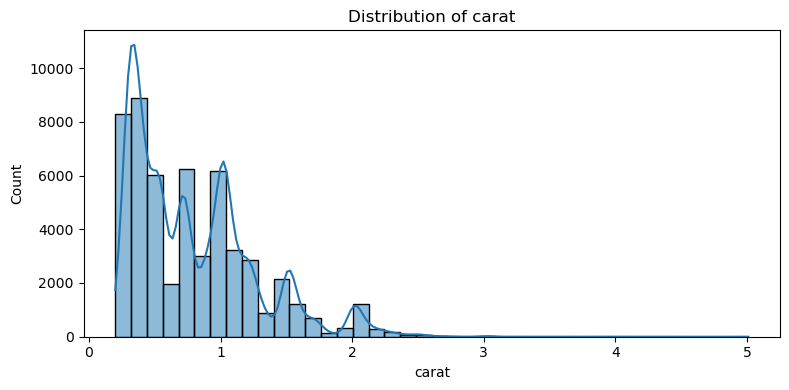

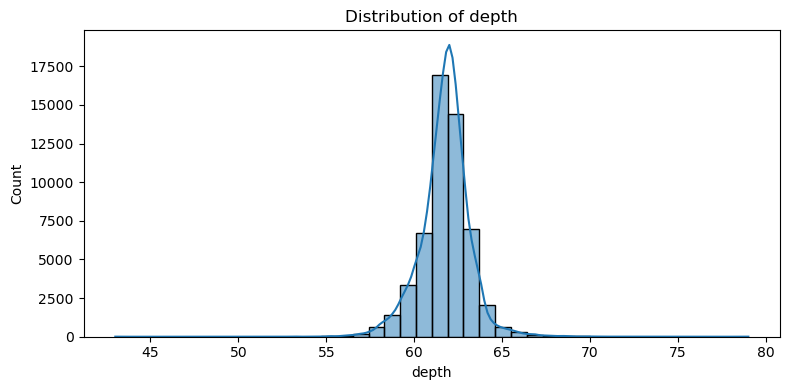

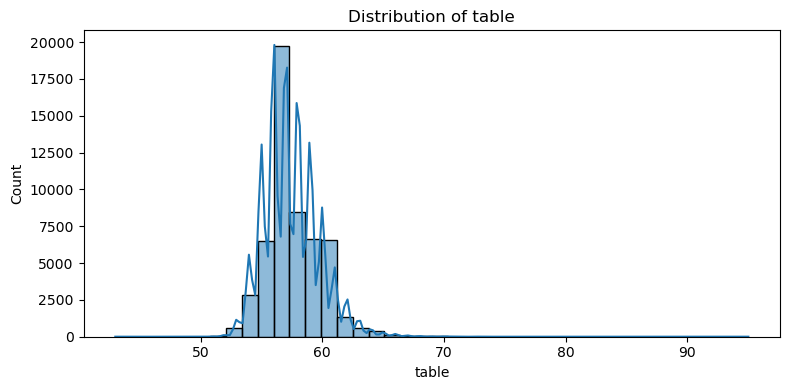

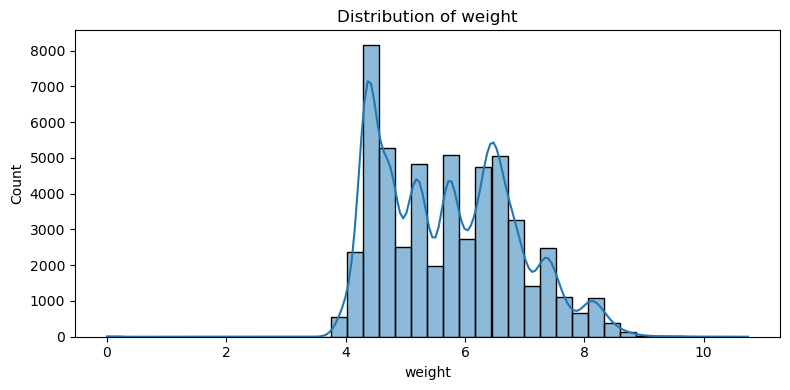

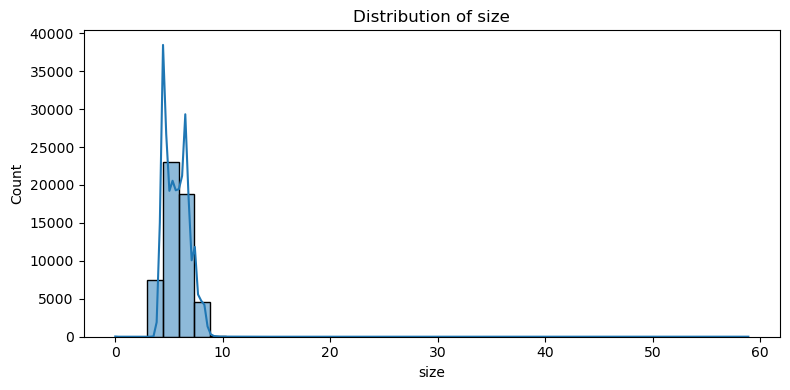

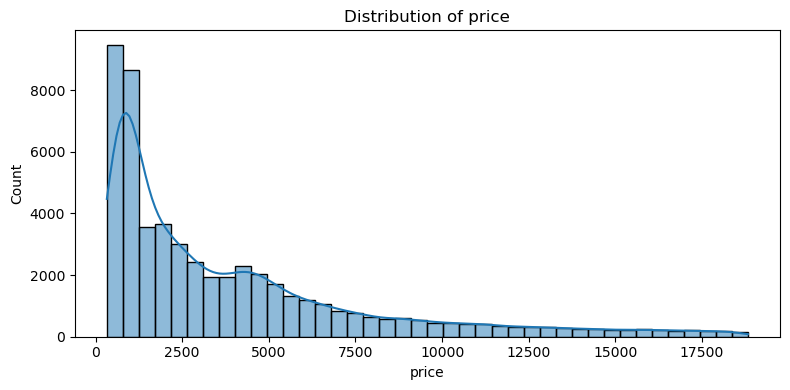

In [10]:
for col in numeric_df.columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=numeric_df, x=col, kde=True, bins=40)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()


## I. Correlation heatmap and conclusions

Pearson correlation measures the strength and direction of a **linear** relationship between numerical variables. It ranges from -1 to +1:
- near +1: strong positive linear association
- near -1: strong negative linear association
- near 0: weak or no linear association

Correlation does not establish causation. Outliers and nonlinear relationships can affect Pearson correlation.

In [ ]:
correlation_matrix = numeric_df.corr(method="pearson")

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap: Numerical Variables")
plt.tight_layout()
plt.show()

display(correlation_matrix.round(3))

# Show pairs with the strongest absolute correlations (excluding self-correlations)
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)
strong_pairs = (
    upper_triangle.stack()
    .rename("correlation")
    .to_frame()
)
strong_pairs["absolute_correlation"] = strong_pairs["correlation"].abs()
display(strong_pairs.sort_values("absolute_correlation", ascending=False).head(10).round(3))


## Conclusion template

After running the notebook, use the outputs to write your final observations. For this dataset, pay particular attention to:
- Which variables have the largest positive or negative skewness.
- Whether log or square-root transformations reduce skewness, and whether Yeo–Johnson helps.
- The number and percentage of potential IQR outliers in each variable.
- How categorical variables were encoded and why encoded category numbers should be interpreted carefully.
- Whether scaling produced the expected ranges.
- Which numeric variables have the strongest positive/negative correlations. Explain the observed relationships without claiming causation.

Do not state that a variable is normally distributed solely because its skewness is close to zero; also inspect the histogram/KDE and consider the overall distribution shape.